# Qwen3.5-9B 벤치마크 표 (A100 Colab 원시 데이터)

GPU를 쓰지 않습니다. 2026-10-17 Colab A100-SXM4-40GB에서 잰 **원시 JSON 3개**를 읽어서
벤치마크 표와 그래프를 만듭니다. 데이터는 `notebooks/assets/qwen3_5_9b_a100_20261017/`에 들어 있습니다.

| 파일 | 만든 스크립트 | 내용 |
|---|---|---|
| `prefill.json` | `scripts/bench_qwen3_5.py` | 1024-token prefill, 128-token decode. torch vs FLA × dynamic vs static cache, HF 기본값 |
| `decode.json` | `scripts/bench_qwen3_5_decode.py` | decode 모드별(sliced-eager / eager / compile / compile-reduce-overhead / cudagraph) ms/token과 수치 차이 |
| `decode_modes.json` | `scripts/validate_qwen3_5_decode_modes.py` | 9개 프롬프트에서 HF 대비 KL·top-1·생성 불일치 |

표와 그래프의 숫자는 모두 위 파일에서 계산됩니다(§4의 주의사항 글에 인용한 값만 예외).

**§5**는 2026-10-19에 같은 A100에서 잰 weight-only INT8(per-channel, group-128) 결과입니다. 데이터는 `notebooks/assets/qwen3_5_9b_int8_a100_20261019/`에 따로 있습니다.

## §0. 데이터 읽기와 출처

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

DATA = Path("assets/qwen3_5_9b_a100_20261017")
if not DATA.exists():  # 저장소 루트에서 연 경우
    DATA = Path("notebooks") / DATA

prefill_raw = json.loads((DATA / "prefill.json").read_text())
decode_raw = json.loads((DATA / "decode.json").read_text())
modes_raw = json.loads((DATA / "decode_modes.json").read_text())


def md_table(header, rows, align=None):
    """Markdown 표로 렌더링한다. pandas 없이 쓰려고 직접 만든다."""
    align = align or ["l"] + ["r"] * (len(header) - 1)
    rule = ["---:" if a == "r" else ":---" for a in align]
    lines = ["| " + " | ".join(header) + " |", "| " + " | ".join(rule) + " |"]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


for name in ("prefill.json", "decode.json", "decode_modes.json"):
    print(f"{name:18s} sha256 {hashlib.sha256((DATA / name).read_bytes()).hexdigest()[:16]}…")
print()
print("device :", prefill_raw["device"])
print("torch  :", prefill_raw["torch"])
a = prefill_raw["args"]
print(f"model  : {a['repo']} ({a['dtype']}), batch {a['batch']}, prompt {a['prompt_tokens']} → new {a['new_tokens']} tokens")

prefill.json       sha256 d7d58f175d2f582b…
decode.json        sha256 c1465dd2e14201dd…
decode_modes.json  sha256 f8d92451469ca974…

device : NVIDIA A100-SXM4-40GB
torch  : 2.11.0+cu130
model  : Qwen/Qwen3.5-9B (bfloat16), batch 1, prompt 1024 → new 128 tokens


## §1. Prefill / decode (표 1)

`bench_qwen3_5.py`의 측정 방식:
- **prefill**: 1024 token을 한 번에 처리하는 시간, warm-up 뒤 3회 평균.
- **decode**: 128 token을 한 개씩 생성하는 구간을 3번 돌려 **최솟값**.
- **HF 기본값**의 decode는 `generate(128)`과 `generate(1)`의 시간 차를 127로 나눈 값입니다(직접 잰 값이 아니라 차분).
- `greedy16`: 처음 16 token이 `torch / dynamic` 결과와 같은지.

In [2]:
rows = prefill_raw["rows"]
name = lambda r: r["kernels"] if r["kernels"] == "hf-default" else f"{r['kernels']} / {'static' if r['static_cache'] else 'dynamic'}"
base = next(r for r in rows if r["kernels"] == "torch" and not r["static_cache"])
hf = next(r for r in rows if r["kernels"] == "hf-default")

md_table(
    ["구현", "prefill ms", "prefill tok/s", "vs torch", "vs HF", "decode ms/tok", "decode tok/s", "peak GiB", "greedy16"],
    [[name(r), f"{r['prefill_ms']:.1f}", f"{r['prefill_tok_per_s']:,.0f}",
      f"{base['prefill_ms'] / r['prefill_ms']:.2f}×", f"{hf['prefill_ms'] / r['prefill_ms']:.2f}×",
      f"{r['decode_ms_per_token']:.1f}", f"{r['decode_tok_per_s']:.1f}",
      f"{r['peak_mem_gib']:.2f}" if "peak_mem_gib" in r else "–",
      {True: "✓", False: "✗", None: "–"}[r.get("greedy16_matches_torch_dynamic")]] for r in rows])
print("vs torch / vs HF: prefill 시간 비 (1보다 크면 그 구현이 빠름)")

| 구현 | prefill ms | prefill tok/s | vs torch | vs HF | decode ms/tok | decode tok/s | peak GiB | greedy16 |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| torch / dynamic | 182.3 | 5,616 | 1.00× | 0.60× | 59.4 | 16.8 | 17.27 | ✓ |
| torch / static | 183.2 | 5,591 | 1.00× | 0.59× | 59.6 | 16.8 | 17.26 | ✓ |
| fla / dynamic | 100.2 | 10,224 | 1.82× | 1.08× | 63.4 | 15.8 | 17.49 | ✓ |
| fla / static | 100.6 | 10,174 | 1.81× | 1.08× | 63.9 | 15.7 | 17.26 | ✓ |
| hf-default | 108.6 | 9,432 | 1.68× | 1.00× | 61.7 | 16.2 | – | – |

vs torch / vs HF: prefill 시간 비 (1보다 크면 그 구현이 빠름)


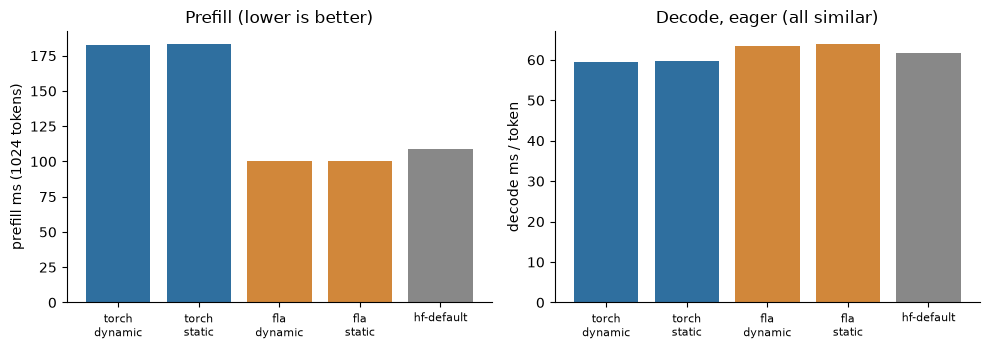

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
labels = [name(r).replace(" / ", "\n") for r in rows]
colors = ["#2f6f9f" if r["kernels"] == "torch" else "#d1873a" if r["kernels"] == "fla" else "#888888" for r in rows]
ax1.bar(labels, [r["prefill_ms"] for r in rows], color=colors)
ax1.set_ylabel("prefill ms (1024 tokens)"); ax1.set_title("Prefill (lower is better)")
ax2.bar(labels, [r["decode_ms_per_token"] for r in rows], color=colors)
ax2.set_ylabel("decode ms / token"); ax2.set_title("Decode, eager (all similar)")
for ax in (ax1, ax2):
    ax.tick_params(axis="x", labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## §2. Decode 모드 (표 2)

`bench_qwen3_5_decode.py`: 같은 prefill 뒤에 token을 하나씩 이어 붙이며 **warm-up 뒤 steady-state ms/token**
(여러 step 평균)을 잽니다. compile / CUDA graph 준비 시간(`prepare_s`, `first_step_s`)은 따로 기록되어 ms/token에 들어가지 않습니다.
수치는 sliced-eager와 **같은 token을 먹였을 때**의 logits 차이입니다.

모드 설명: `sliced-eager`는 기존 경로(캐시를 매 step 잘라 씀), 나머지는 고정 shape 경로입니다.
`fla-delta`는 FLA 커널을 delta-rule에만 쓰고 conv는 torch로 둔 구성입니다.

In [4]:
drows = decode_raw["rows"]
MODE_ORDER = ["sliced-eager", "eager", "compile", "compile-reduce-overhead", "cudagraph"]
by = {(r["kernels"], r["mode"]): r for r in drows}
hf_ms = hf["decode_ms_per_token"]

out = []
for kernels in ("torch", "fla-delta"):
    sliced = by[(kernels, "sliced-eager")]["ms_per_token"]
    for mode in MODE_ORDER:
        r = by[(kernels, mode)]
        out.append([kernels, mode, f"{r['ms_per_token']:.2f}", f"{1000 / r['ms_per_token']:.1f}",
                    f"{sliced / r['ms_per_token']:.2f}×", f"{hf_ms / r['ms_per_token']:.2f}×",
                    f"{r['first_step_s']:.1f}", f"{r['prepare_s']:.2f}",
                    f"{r['argmax_agreement']:.3f}", f"{r['logits_max_abs_diff']:.3f}",
                    r.get("graph_breaks", "–")])
md_table(["kernels", "mode", "ms/tok", "tok/s", "vs 자기 sliced-eager", "vs HF 기본", "첫 step s", "prepare s",
          "argmax 일치", "max|Δlogit|", "graph breaks"], out, ["l", "l"] + ["r"] * 9)
print(f"HF 기본 decode 기준값 {hf_ms:.1f} ms/tok (표 1)")

| kernels | mode | ms/tok | tok/s | vs 자기 sliced-eager | vs HF 기본 | 첫 step s | prepare s | argmax 일치 | max|Δlogit| | graph breaks |
| :--- | :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| torch | sliced-eager | 61.53 | 16.3 | 1.00× | 1.00× | 0.1 | 0.00 | 1.000 | 0.000 | – |
| torch | eager | 61.72 | 16.2 | 1.00× | 1.00× | 0.1 | 0.00 | 1.000 | 0.188 | – |
| torch | compile | 16.98 | 58.9 | 3.62× | 3.63× | 7.7 | 0.00 | 1.000 | 0.156 | 0 |
| torch | compile-reduce-overhead | 16.09 | 62.2 | 3.82× | 3.84× | 8.3 | 0.00 | 1.000 | 0.156 | 0 |
| torch | cudagraph | 19.89 | 50.3 | 3.09× | 3.10× | 0.0 | 0.26 | 1.000 | 0.188 | – |
| fla-delta | sliced-eager | 55.02 | 18.2 | 1.00× | 1.12× | 0.1 | 0.00 | 1.000 | 0.000 | – |
| fla-delta | eager | 56.02 | 17.8 | 0.98× | 1.10× | 0.1 | 0.00 | 1.000 | 0.279 | – |
| fla-delta | compile | 17.02 | 58.7 | 3.23× | 3.63× | 21.7 | 0.00 | 0.979 | 0.188 | 0 |
| fla-delta | compile-reduce-overhead | 15.08 | 66.3 | 3.65× | 4.09× | 21.8 | 0.00 | 0.979 | 0.188 | 0 |
| fla-delta | cudagraph | 18.26 | 54.8 | 3.01× | 3.38× | 0.0 | 0.23 | 1.000 | 0.279 | – |

HF 기본 decode 기준값 61.7 ms/tok (표 1)


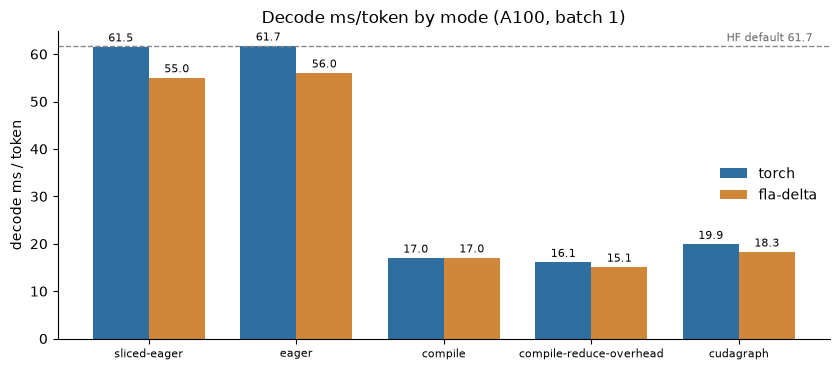

In [5]:
import numpy as np

fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(len(MODE_ORDER)); w = 0.38
for i, (kernels, color) in enumerate((("torch", "#2f6f9f"), ("fla-delta", "#d1873a"))):
    vals = [by[(kernels, m)]["ms_per_token"] for m in MODE_ORDER]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=kernels, color=color)
    ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
ax.axhline(hf_ms, ls="--", color="#888", lw=1); ax.text(len(MODE_ORDER) - 0.5, hf_ms + 1, f"HF default {hf_ms:.1f}", ha="right", fontsize=8, color="#666")
ax.set_xticks(x, MODE_ORDER, fontsize=8); ax.set_ylabel("decode ms / token"); ax.set_title("Decode ms/token by mode (A100, batch 1)")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### 파생 지표 — 메모리 대역폭 한계

batch 1 decode는 token마다 가중치 전체를 HBM에서 한 번 읽습니다. 가중치 크기를 peak 메모리로 근사하고
A100-SXM4-40GB의 HBM 대역폭(1555 GB/s, spec sheet 값)으로 나누면 ms/token의 **어림 하한**이 됩니다.
peak에는 활성값·캐시가 조금 섞여 있으므로 하한은 약간 높게 잡힌 값입니다.

In [6]:
HBM_GBPS = 1555
peak_gib = next(r["peak_mem_gib"] for r in rows if r["kernels"] == "torch" and r["static_cache"])
floor_ms = peak_gib * 2**30 / (HBM_GBPS * 1e9) * 1e3
print(f"읽는 바이트 ≈ peak {peak_gib:.2f} GiB → 하한 ≈ {floor_ms:.1f} ms/token ({1000 / floor_ms:.0f} tok/s)\n")
md_table(["구성", "ms/tok", "하한 대비 달성률", "하한과의 격차 ms"],
         [[f"{k}:{m}", f"{by[(k, m)]['ms_per_token']:.2f}", f"{floor_ms / by[(k, m)]['ms_per_token']:.0%}",
           f"{by[(k, m)]['ms_per_token'] - floor_ms:.1f}"]
          for k in ("torch", "fla-delta") for m in ("sliced-eager", "compile-reduce-overhead", "cudagraph")])

읽는 바이트 ≈ peak 17.26 GiB → 하한 ≈ 11.9 ms/token (84 tok/s)



| 구성 | ms/tok | 하한 대비 달성률 | 하한과의 격차 ms |
| :--- | ---: | ---: | ---: |
| torch:sliced-eager | 61.53 | 19% | 49.6 |
| torch:compile-reduce-overhead | 16.09 | 74% | 4.2 |
| torch:cudagraph | 19.89 | 60% | 8.0 |
| fla-delta:sliced-eager | 55.02 | 22% | 43.1 |
| fla-delta:compile-reduce-overhead | 15.08 | 79% | 3.2 |
| fla-delta:cudagraph | 18.26 | 65% | 6.3 |

## §3. HF 대비 정확도 (표 3)

9개 프롬프트로 `transformers` 구현과 비교한 결과를 (kernels, mode)별로 접었습니다.

- **mean KL / min top-1**: 프롬프트 마지막 최대 32 위치의 logits 분포 차이. KL은 프롬프트별 값의 단순 평균이고, token이 1개인 `hello`는 제외됩니다. 짧은 프롬프트는 위치 수가 적습니다.
- **teacher-forced 불일치**: HF가 만든 token을 먹였을 때 다음 token이 HF와 다른 step. HF의 top-1/top-2 margin이
  0.5 이하면 near-tie(bf16 반올림으로 뒤집힐 수 있음), 넘으면 strong. **strong이 0이면 불일치가 전부 HF의 1·2위 logit이 거의 같은 자리에서 갈린 것**이라는 뜻입니다.
- **free-run 일치**: 192 token을 자유 생성해서 HF와 끝까지 같은 프롬프트 수. 한 번 갈라지면 뒤가 계속 달라지므로 엄격한 지표입니다.

In [7]:
PROMPTS = [r["prompt"] for r in modes_raw["rows"] if r["kernels"] == "torch" and r["mode"] == "sliced-eager" and not r.get("summary")]
per = {}
for r in modes_raw["rows"]:
    key = (r["kernels"], r["mode"])
    d = per.setdefault(key, {"rows": [], "summary": None})
    (d.__setitem__("summary", r) if r.get("summary") else d["rows"].append(r))

out = []
for (kernels, mode), d in per.items():
    s, rs = d["summary"], d["rows"]
    if "error" in s:
        out.append([kernels, mode, "–", "–", "–", "–", "–", "–", f"실패: {s['error'].splitlines()[0][:44]}…"])
        continue
    kl = [r["decode_kl_vs_hf"] for r in rs if "decode_kl_vs_hf" in r]
    top1 = [r["decode_top1_vs_hf"] for r in rs if "decode_top1_vs_hf" in r]
    strong = sum(r["tf_mismatch_strong"] for r in rs)
    near = sum(r["tf_mismatch_near_tie"] for r in rs)
    exact = sum(r["gen_first_mismatch"] is None for r in rs)
    out.append([kernels, mode, f"{sum(kl) / len(kl):.2e}", f"{min(top1):.3f}", strong, near, f"{exact}/{len(rs)}",
                s.get("dynamo_unique_graphs") or "–", ""])
md_table(["kernels", "mode", "mean KL", "min top-1", "strong", "near-tie", "free-run 일치", "graphs", "비고"], out,
         ["l", "l"] + ["r"] * 6 + ["l"])
print("strong 합계:", sum(row[4] for row in out if isinstance(row[4], int)))

| kernels | mode | mean KL | min top-1 | strong | near-tie | free-run 일치 | graphs | 비고 |
| :--- | :--- | ---: | ---: | ---: | ---: | ---: | ---: | :--- |
| torch | sliced-eager | 4.70e-04 | 1.000 | 0 | 7 | 5/9 | – |  |
| torch | eager | 4.58e-04 | 1.000 | 0 | 13 | 4/9 | – |  |
| torch | compile | 4.00e-04 | 0.968 | 0 | 12 | 4/9 | 1 |  |
| torch | compile-reduce-overhead | 4.00e-04 | 0.968 | 0 | 12 | 4/9 | 1 |  |
| torch | cudagraph | 4.58e-04 | 1.000 | 0 | 13 | 4/9 | – |  |
| fla-delta | sliced-eager | 4.36e-04 | 0.947 | 0 | 9 | 4/9 | – |  |
| fla-delta | cudagraph | 3.95e-04 | 0.947 | 0 | 7 | 5/9 | – |  |
| fla-delta | compile-reduce-overhead | 4.05e-04 | 0.938 | 0 | 9 | 4/9 | 1 |  |
| fla | sliced-eager | 4.20e-04 | 0.968 | 0 | 8 | 5/9 | – |  |
| fla | cudagraph | 4.33e-04 | 1.000 | 0 | 12 | 3/9 | – |  |
| fla | compile-reduce-overhead | – | – | – | – | – | – | 실패: Unsupported: Skip calling `torch.compiler.di… |

strong 합계: 0


### 프롬프트별 KL

KL이 프롬프트 길이에 얼마나 민감한지 봅니다(`decode_kl_vs_hf`, 낮을수록 HF와 가깝습니다).
`hello`는 token이 1개라 decode 구간 지표가 없어 `–`입니다.

In [8]:
configs = [k for k, d in per.items() if "error" not in d["summary"]]
cell_of = lambda cfg, p: next((r for r in per[cfg]["rows"] if r["prompt"] == p), {})
md_table(["prompt (tokens)"] + [f"{k}:{m}" for k, m in configs],
         [[f"{p} ({cell_of(configs[0], p)['tokens']})"] +
          [f"{cell_of(c, p)['decode_kl_vs_hf']:.1e}" if "decode_kl_vs_hf" in cell_of(c, p) else "–" for c in configs]
          for p in PROMPTS])

| prompt (tokens) | torch:sliced-eager | torch:eager | torch:compile | torch:compile-reduce-overhead | torch:cudagraph | fla-delta:sliced-eager | fla-delta:cudagraph | fla-delta:compile-reduce-overhead | fla:sliced-eager | fla:cudagraph |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| short (5) | 5.5e-04 | 5.5e-04 | 2.7e-04 | 2.7e-04 | 5.5e-04 | 3.9e-04 | 3.9e-04 | 2.1e-04 | 6.5e-04 | 6.5e-04 |
| hello (1) | – | – | – | – | – | – | – | – | – | – |
| korean (20) | 4.5e-04 | 4.5e-04 | 6.0e-04 | 6.0e-04 | 4.5e-04 | 4.4e-04 | 3.4e-04 | 5.4e-04 | 4.5e-04 | 4.5e-04 |
| math (43) | 5.5e-04 | 7.5e-04 | 6.0e-04 | 6.0e-04 | 7.5e-04 | 4.8e-04 | 5.1e-04 | 6.3e-04 | 6.0e-04 | 5.6e-04 |
| chat (23) | 3.0e-04 | 3.5e-04 | 2.3e-04 | 2.3e-04 | 3.5e-04 | 3.5e-04 | 3.3e-04 | 2.8e-04 | 3.4e-04 | 3.5e-04 |
| chat_long (32) | 6.2e-04 | 6.0e-04 | 5.8e-04 | 5.8e-04 | 6.0e-04 | 6.5e-04 | 5.5e-04 | 7.7e-04 | 6.3e-04 | 6.8e-04 |
| prose_1k (1057) | 2.0e-04 | 2.0e-04 | 2.0e-04 | 2.0e-04 | 2.0e-04 | 2.3e-04 | 2.0e-04 | 2.2e-04 | 8.1e-05 | 8.7e-05 |
| code_1k (1000) | 2.2e-04 | 2.2e-04 | 1.0e-04 | 1.0e-04 | 2.2e-04 | 3.5e-04 | 2.7e-04 | 1.8e-04 | 1.9e-04 | 1.6e-04 |
| code_1_5k (1500) | 8.6e-04 | 5.4e-04 | 6.1e-04 | 6.1e-04 | 5.4e-04 | 6.0e-04 | 5.6e-04 | 4.0e-04 | 4.2e-04 | 5.1e-04 |

### 실패한 설정

In [9]:
for (kernels, mode), d in per.items():
    if "error" in d["summary"]:
        print(f"{kernels}:{mode}\n")
        print(d["summary"]["error"][:400])

fla:compile-reduce-overhead

Unsupported: Skip calling `torch.compiler.disable()`d function
  Explanation: Skip calling function `<function causal_conv1d_fwd at 0x7c1e8ef0a700>` since it was wrapped with `torch.compiler.disable` (reason: None)
  Hint: Remove the `torch.compiler.disable` call

  Developer debug context: <function causal_conv1d_fwd at 0x7c1e8ef0a700>

 For more details about this graph break, please visit: http


## §4. 읽을 때 주의할 점

1. **표 1과 표 2의 decode 숫자는 같은 구성이어도 달라집니다.** 표 1의 `torch / dynamic`은 59.4 ms, 표 2의 `torch:sliced-eager`는 61.5 ms 입니다.
   스크립트·캐시 구현·측정 구간(최솟값 vs 평균)이 달라서 생기는 약 3–4%의 차이이고, 두 표를 섞어 계산하지 마세요.
   표 2의 "vs HF 기본"은 표 2의 값을 표 1의 HF 값으로 나눈 것이므로 방법이 다른 숫자끼리의 비교입니다.
2. **측정은 1회 실행**입니다(반복 간 분산은 저장되어 있지 않습니다). 몇 % 차이는 해석하지 마세요.
3. **batch 1, 1024 token 컨텍스트, 랜덤 입력 token**의 결과입니다. 생성 품질 평가가 아닙니다.
4. 표 1의 prefill은 FLA 커널 쪽이 약 1.8배 빠르지만 decode는 오히려 소폭 느립니다(63 vs 59 ms).
   decode는 launch 오버헤드가 지배적이라 커널 선택보다 고정 shape + CUDA graph 여부가 훨씬 큰 영향을 줍니다(표 2).
5. 정확도에서 `fla-delta`/`fla`의 top-1이 0.94~0.97까지 내려가는 것은 짧은 프롬프트(`korean`·`math`·`chat_long`)에서
   비교 위치가 19~32개뿐이라 한두 token이 뒤집힌 결과입니다. 실패한 설정을 뺀 모든 설정에서 strong 불일치는 0입니다(표 3).

## §5. Weight-only INT8 (2026-10-19)

같은 A100-SXM4-40GB에서 bf16 가중치를 int8로 바꿨을 때 decode가 얼마나 빨라지고 정확도가 얼마나 남는지 봅니다.
데이터는 `notebooks/assets/qwen3_5_9b_int8_a100_20261019/`에 있습니다. 구현은 `infer_opt/quant.py`와 `infer_opt/quant_kernels.py`입니다.

- **per-channel**: 출력 채널마다 scale 1개(`scale = max|w| / 127`).
- **group-128**: 출력 채널마다, 입력 128열마다 scale 1개. 클리핑은 없고 그룹마다 absmax를 씁니다.
- **`int8`**: lm_head와 출력 32개짜리 delta-rule gate projection을 뺀 모든 Linear. **`int8+lm_head`**: lm_head까지.
- 모든 측정은 Qwen3.5-9B, batch 1, `fla-delta:compile-reduce-overhead`입니다. INT8 구성은 inductor `max_autotune`과 `coordinate_descent_tuning`을 켰습니다.

| 파일 | 만든 스크립트 | 내용 |
|---|---|---|
| `decode_per_channel.json`, `decode_group128.json` | `scripts/bench_qwen3_5_int8_decode.py` | 같은 세션에서 잰 최종 decode 속도와 bf16 대비 수치 차이 |
| `gate_per_channel.json`, `gate_group128.json` | `scripts/validate_qwen3_5_decode_modes.py` | HF 대비 정확도와 양자화 기준(gate) |
| `gate_group128_dequant_mm.json`, `gate_group128_inductor_reduction.json` | 같음 | 이전 구현으로 잰 group-128 gate (반복 간 차이 확인용) |
| `decode_group128_*.json` | `scripts/bench_qwen3_5_int8_decode.py` | group-128 구현을 바꿔 가며 잰 decode 속도 |
| `group_gemv_tune.json` | `scripts/tune_qwen3_5_group_gemv.py`의 초기판 | 실제 9B 가중치로 잰 shape별 커널 설정과 decode 속도 |

In [10]:
INT8 = Path("assets/qwen3_5_9b_int8_a100_20261019")
if not INT8.exists():  # 저장소 루트에서 연 경우
    INT8 = Path("notebooks") / INT8
int8 = {p.stem: json.loads(p.read_text()) for p in sorted(INT8.glob("*.json"))}
for p in sorted(INT8.glob("*.json")):
    print(f"{p.name:44s} sha256 {hashlib.sha256(p.read_bytes()).hexdigest()[:16]}…")

decode_group128.json                         sha256 8de45e55d40d7e20…
decode_group128_dequant_mm.json              sha256 a848a73c89866f31…
decode_group128_inductor_reduction.json      sha256 976a7b4c7ab1cc02…
decode_group128_triton_autotune.json         sha256 5615c3a2b711def3…
decode_per_channel.json                      sha256 16080f4d6ffd0dde…
gate_group128.json                           sha256 1c5f309f611bf580…
gate_group128_dequant_mm.json                sha256 a2522e2420ed3785…
gate_group128_inductor_reduction.json        sha256 52a24a79b877b8a3…
gate_per_channel.json                        sha256 7c998bf58c91cb32…
group_gemv_tune.json                         sha256 ed8385d68c8ced74…


### 표 5. 최종 decode 속도 (같은 세션)

`bench_qwen3_5_int8_decode.py`는 모델을 한 번 올린 뒤 bf16 → `int8` → `int8+lm_head` 순서로 제자리 양자화하며 잽니다.
랜덤 1024-token 프롬프트 뒤 warm-up 3 step, 그다음 128 token의 평균 ms/token입니다.
수치는 양자화 전에 기록한 bf16 sliced-eager logits에 같은 token 48개를 먹였을 때의 차이입니다(KL(bf16 ‖ int8)의 step 평균, argmax 일치율).
per-channel과 group-128은 같은 A100 세션의 다른 프로세스라서 각 파일에 bf16 대조가 하나씩 있습니다.

In [11]:
LABEL = {"decode_per_channel": "per-channel", "decode_group128": "group-128"}
final = []
for key, scheme in LABEL.items():
    rows5 = {r["config"]: r for r in int8[key]["rows"]}
    for cfg, r in rows5.items():
        final.append((scheme, cfg, r, rows5["bf16"]["ms_per_token"]))

md_table(["양자화", "구성", "ms/tok", "tok/s", "vs bf16", "KL vs bf16", "argmax 일치", "max |Δlogit|", "peak GiB"],
         [[s if c != "bf16" else f"({s} 실행)", c, f"{r['ms_per_token']:.2f}", f"{1000 / r['ms_per_token']:.1f}",
           f"{b / r['ms_per_token']:.2f}×", f"{r['mean_kl_vs_bf16']:.5f}", f"{r['argmax_agreement']:.3f}",
           f"{r['logits_max_abs_diff']:.3f}", f"{r['peak_mem_gib']:.2f}"] for s, c, r, b in final])
print("bf16 행의 KL은 compile된 bf16 decode와 sliced-eager bf16의 차이(구현 간 반올림 차이)입니다.")
print("peak GiB에는 prefill이 포함됩니다. group-128 int8+lm_head의 prefill은 lm_head를 bf16으로 역양자화해서 1.5 GiB 높습니다.")

| 양자화 | 구성 | ms/tok | tok/s | vs bf16 | KL vs bf16 | argmax 일치 | max |Δlogit| | peak GiB |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| (per-channel 실행) | bf16 | 15.04 | 66.5 | 1.00× | 0.00024 | 1.000 | 0.188 | 17.30 |
| per-channel | int8 | 9.80 | 102.1 | 1.53× | 0.00085 | 1.000 | 0.750 | 10.86 |
| per-channel | int8+lm_head | 8.92 | 112.2 | 1.69× | 0.00092 | 1.000 | 0.828 | 11.81 |
| (group-128 실행) | bf16 | 15.09 | 66.3 | 1.00× | 0.00024 | 1.000 | 0.188 | 17.30 |
| group-128 | int8 | 10.79 | 92.7 | 1.40× | 0.00051 | 1.000 | 0.430 | 10.96 |
| group-128 | int8+lm_head | 10.15 | 98.5 | 1.49× | 0.00057 | 1.000 | 0.422 | 13.35 |

bf16 행의 KL은 compile된 bf16 decode와 sliced-eager bf16의 차이(구현 간 반올림 차이)입니다.
peak GiB에는 prefill이 포함됩니다. group-128 int8+lm_head의 prefill은 lm_head를 bf16으로 역양자화해서 1.5 GiB 높습니다.


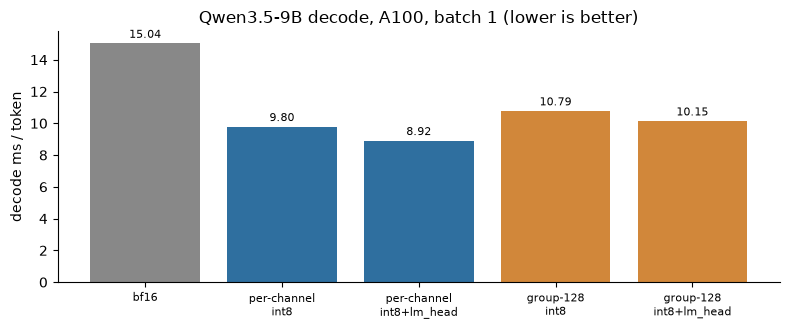

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.4))
show = [(s, c, r) for s, c, r, _ in final if not (c == "bf16" and s == "group-128")]
labels = ["bf16" if c == "bf16" else f"{s}\n{c}" for s, c, _ in show]
colors = ["#888888" if c == "bf16" else "#2f6f9f" if s == "per-channel" else "#d1873a" for s, c, _ in show]
bars = ax.bar(labels, [r["ms_per_token"] for _, _, r in show], color=colors)
ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax.set_ylabel("decode ms / token"); ax.set_title("Qwen3.5-9B decode, A100, batch 1 (lower is better)")
ax.tick_params(axis="x", labelsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### 표 6. 정확도 기준 (gate)

`validate_qwen3_5_decode_modes.py`가 §3과 같은 9개 프롬프트로 HF와 비교합니다. 같은 실행 안의 bf16 구성(같은 kernels:mode)을 대조로 씁니다.

- **KL 비율** = 양자화 구성의 평균 decode KL(HF 대비) ÷ bf16 구성의 평균 decode KL. **2 이하**여야 합니다.
- **strong 불일치**(teacher-forced, HF margin > 0.5)가 **0**이어야 합니다.
- 두 조건을 모두 만족하면 통과입니다.

In [13]:
def gate_rows(key, scheme):
    out = []
    for g in int8[key]["gate"]:
        b, q = g["bf16"], g["quantized"]
        out.append([scheme, g["config"].split(":")[-1], f"{b['mean_kl']:.6f}", f"{q['mean_kl']:.6f}", f"{g['kl_ratio']:.2f}",
                    q["strong_mismatches"], q["near_tie_mismatches"], f"{q['free_run_identical']}/{q['prompts']}",
                    "통과" if g["pass"] else "**실패**"])
    return out

md_table(["양자화", "구성", "bf16 KL", "int8 KL", "KL 비율 (≤2)", "strong", "near-tie", "free-run 일치", "판정"],
         gate_rows("gate_per_channel", "per-channel") + gate_rows("gate_group128", "group-128 (Triton GEMV)"))

| 양자화 | 구성 | bf16 KL | int8 KL | KL 비율 (≤2) | strong | near-tie | free-run 일치 | 판정 |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| per-channel | int8 | 0.000457 | 0.000979 | 2.14 | 1 | 15 | 1/9 | **실패** |
| per-channel | int8+lm_head | 0.000457 | 0.001126 | 2.47 | 1 | 13 | 1/9 | **실패** |
| group-128 (Triton GEMV) | int8 | 0.000405 | 0.000766 | 1.89 | 0 | 12 | 5/9 | 통과 |
| group-128 (Triton GEMV) | int8+lm_head | 0.000405 | 0.000789 | 1.95 | 0 | 10 | 6/9 | 통과 |

#### group-128 gate의 반복 간 차이

group-128 gate를 구현만 바꿔 세 번 쟀습니다. 셋 다 같은 양자화 값을 쓰고 누적 순서만 조금 다릅니다.
KL 비율의 분모인 bf16 KL(우리 bf16 구현과 HF의 차이)이 실행마다 달라져서 비율도 움직입니다.

In [14]:
RUNS = [("역양자화 후 matmul", "gate_group128_dequant_mm"), ("inductor reduction", "gate_group128_inductor_reduction"),
        ("Triton GEMV (현재)", "gate_group128")]
out = []
for label, key in RUNS:
    g8, g8l = int8[key]["gate"]
    out.append([label, f"{g8['bf16']['mean_kl']:.6f}", f"{g8['quantized']['mean_kl']:.6f}", f"{g8['kl_ratio']:.2f}",
                g8["quantized"]["strong_mismatches"], f"{g8l['quantized']['mean_kl']:.6f}", f"{g8l['kl_ratio']:.2f}",
                g8l["quantized"]["strong_mismatches"]])
md_table(["구현", "bf16 KL", "int8 KL", "int8 비율", "int8 strong", "int8+lm_head KL", "int8+lm_head 비율", "int8+lm_head strong"], out)

| 구현 | bf16 KL | int8 KL | int8 비율 | int8 strong | int8+lm_head KL | int8+lm_head 비율 | int8+lm_head strong |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 역양자화 후 matmul | 0.000457 | 0.000706 | 1.55 | 0 | 0.000768 | 1.68 | 0 |
| inductor reduction | 0.000457 | 0.000716 | 1.57 | 0 | 0.000787 | 1.72 | 1 |
| Triton GEMV (현재) | 0.000405 | 0.000766 | 1.89 | 0 | 0.000789 | 1.95 | 0 |

### 표 7. group-128 decode 구현별 속도

group-128은 scale이 합(reduction) 방향으로 바뀌어서 per-channel처럼 출력에 scale을 한 번 곱할 수 없습니다. 구현마다 속도가 크게 달랐습니다.

1. **역양자화 후 matmul**: `F.linear(x, q * scale)`. inductor가 그룹 scale 곱을 matmul 안으로 합치지 못했습니다.
2. **inductor reduction**: 1 token일 때 그룹별 부분합 → scale 곱 → 합을 PyTorch 연산으로 쓰고 inductor가 커널을 만들게 했습니다.
3. **Triton GEMV + autotune**: 직접 짠 커널에 `triton.autotune`. compile + CUDA graph 안에서 고른 설정이 나빠서 lm_head까지 양자화하면 bf16보다 느렸습니다.
4. **Triton GEMV, 고정 기본 설정** (8, 2, 4, 2)과 **shape별 최적 설정**: `group_gemv_tune.json`. `int8+lm_head`만 쟀습니다.
5. **Triton GEMV + shape 규칙 (현재)**: `launch_config`가 shape에서 설정을 정합니다.

1–3과 5는 각각 다른 프로세스라 bf16 대조 값도 함께 적었습니다.

In [15]:
def ms(key, cfg):
    return next(r["ms_per_token"] for r in int8[key]["rows"] if r["config"] == cfg)

tune = int8["group_gemv_tune"]
hist = [("역양자화 후 matmul", "decode_group128_dequant_mm"), ("inductor reduction", "decode_group128_inductor_reduction"),
        ("Triton GEMV + autotune", "decode_group128_triton_autotune")]
out = [[label, f"{ms(k, 'int8'):.2f}", f"{ms(k, 'int8+lm_head'):.2f}", f"{ms(k, 'bf16'):.2f}"] for label, k in hist]
out += [["Triton GEMV, 고정 기본 설정", "–", f"{tune['default']['ms_per_token']:.2f}", "–"],
        ["Triton GEMV, shape별 최적 설정", "–", f"{tune['tuned']['ms_per_token']:.2f}", "–"],
        ["**Triton GEMV + shape 규칙 (현재)**", f"{ms('decode_group128', 'int8'):.2f}", f"{ms('decode_group128', 'int8+lm_head'):.2f}",
         f"{ms('decode_group128', 'bf16'):.2f}"],
        ["(참고) per-channel", f"{ms('decode_per_channel', 'int8'):.2f}", f"{ms('decode_per_channel', 'int8+lm_head'):.2f}",
         f"{ms('decode_per_channel', 'bf16'):.2f}"]]
md_table(["group-128 구현", "int8 ms/tok", "int8+lm_head ms/tok", "같은 실행의 bf16 ms/tok"], out)

| group-128 구현 | int8 ms/tok | int8+lm_head ms/tok | 같은 실행의 bf16 ms/tok |
| :--- | ---: | ---: | ---: |
| 역양자화 후 matmul | 14.28 | 14.59 | 15.12 |
| inductor reduction | 13.39 | 13.03 | 15.11 |
| Triton GEMV + autotune | 12.75 | 25.41 | 15.08 |
| Triton GEMV, 고정 기본 설정 | – | 13.29 | – |
| Triton GEMV, shape별 최적 설정 | – | 10.19 | – |
| **Triton GEMV + shape 규칙 (현재)** | 10.79 | 10.15 | 15.09 |
| (참고) per-channel | 9.80 | 8.92 | 15.04 |

### 표 8. shape별 GEMV 커널 시간 (실제 9B 가중치)

`group_gemv_tune.json`: 같은 shape의 모듈을 차례로 부르는 CUDA graph를 설정마다 재생해 1회당 시간을 잽니다.
모듈 가중치를 합치면 L2(40 MB)보다 커서 decode처럼 HBM에서 읽습니다. 설정은 `(BLOCK_N, UNROLL, num_warps, num_stages)`입니다.
GB/s는 int8 가중치와 bf16 scale(128열마다 2바이트)을 읽은 양 기준입니다. 현재 `launch_config` 규칙은 이 측정에서 나왔습니다.

In [16]:
import ast

srows, total_default, total_best = [], 0.0, 0.0
for key, v in tune["shapes"].items():
    n, k, g = ast.literal_eval(key)
    total_default += v["default_us"] * v["count"]; total_best += v["best_us"] * v["count"]
    srows.append([f"{n} × {k}", v["count"], f"{n * k / 2**20:.0f}", f"{v['default_us']:.1f}", str(tuple(v["best"])),
                  f"{v['best_us']:.1f}", f"{v['best_GBps']:,.0f}", f"{v['best_us'] * v['count'] / 1e3:.2f}"])
md_table(["weight [N × K]", "step당 호출", "int8 MiB", "기본 설정 µs", "최적 설정", "최적 µs", "GB/s", "step당 ms (최적)"], srows)
print(f"step당 GEMV 합: 기본 설정 {total_default / 1e3:.2f} ms → 최적 설정 {total_best / 1e3:.2f} ms")
print(f"decode ms/token (int8+lm_head): 기본 {tune['default']['ms_per_token']:.2f} → 최적 {tune['tuned']['ms_per_token']:.2f}")

| weight [N × K] | step당 호출 | int8 MiB | 기본 설정 µs | 최적 설정 | 최적 µs | GB/s | step당 ms (최적) |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 12288 × 4096 | 64 | 48 | 71.4 | (32, 4, 8, 3) | 45.4 | 1,125 | 2.91 |
| 4096 × 12288 | 32 | 48 | 78.9 | (8, 8, 8, 4) | 50.6 | 1,010 | 1.62 |
| 8192 × 4096 | 32 | 32 | 34.4 | (16, 2, 8, 3) | 30.2 | 1,127 | 0.97 |
| 248320 × 4096 | 1 | 970 | 835.1 | (32, 4, 8, 3) | 722.4 | 1,430 | 0.72 |
| 4096 × 4096 | 56 | 16 | 27.9 | (8, 8, 8, 2) | 18.6 | 915 | 1.04 |
| 1024 × 4096 | 16 | 4 | 26.0 | (4, 8, 8, 2) | 9.8 | 435 | 0.16 |

step당 GEMV 합: 기본 설정 11.01 ms → 최적 설정 7.42 ms
decode ms/token (int8+lm_head): 기본 13.29 → 최적 10.19


### §5 읽을 때 주의할 점

1. **gate 여유는 생각보다 작습니다.** group-128 `int8`의 KL 비율은 실행에 따라 1.55–1.89였습니다. int8 KL 자체는 0.00071–0.00077로
   안정적인데, 분모인 bf16 KL이 실행마다 0.00041–0.00046으로 움직였습니다. `int8+lm_head`는 한 번 strong 불일치 1개로 실패한 적이 있습니다
   (`prose_1k`에서 HF margin 1.75인 token, per-channel도 같은 자리에서 틀립니다).
2. **per-channel이 여전히 1.2 ms/token 빠릅니다**(`int8+lm_head` 8.92 vs 10.15). 차이는 특정 레이어가 아니라 여섯 shape 전체에 퍼져 있습니다(표 8).
3. **표 7의 구현들은 서로 다른 세션·프로세스에서 잰 값**입니다. 같은 세션 비교는 표 5뿐입니다. bf16 대조는 15.0–15.1 ms로 안정적이었습니다.
4. 측정은 각 구성 **1회 실행**입니다. 몇 % 차이는 해석하지 마세요.
5. Qwen3.5-0.8B(로컬 RTX 2080 SUPER)는 group-128로도 gate를 넘지 못했습니다(KL 비율 약 2.1–2.4). group 32에서 1.89로 통과했습니다. 이 노트북의 숫자는 모두 9B입니다.
6. K 방향을 나누는 split-K(down_proj 4096 × 12288)는 1회당 48.8 vs 50.6 µs로 decode 전체에서는 차이가 없어 넣지 않았습니다.